# Plant Disease Detection using CNN

This notebook provides a complete end-to-end deep learning workflow for plant disease detection using a Convolutional Neural Network (CNN).

The workflow includes:

1. Check and validate the PlantVillage dataset.
2. Perform exploratory data analysis (EDA) and visualize sample images and class distribution.
3. Create reproducible and stratified training, validation, and test splits.
4. Build efficient TensorFlow data pipelines for image processing.
5. Apply data augmentation to improve model generalization.
6. Build and train a CNN model for plant disease classification.
7. Evaluate the trained model on training, validation, and test datasets using accuracy and loss.
8. Analyze model performance using a classification report and confusion matrix.
9. Predict the disease class of a new leaf image with a confidence score.
10. Save the trained model and class names for future use.


## 1. Install required packages

Run this cell only when the packages are not installed.
Remove the `#` at the beginning before running it.


In [1]:
%pip install tensorflow scikit-learn matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

- `Path` handles file and folder paths safely.
- `NumPy` performs numerical operations.
- `Matplotlib` creates graphs.
- `TensorFlow/Keras` builds and trains the CNN.
- `train_test_split` creates reproducible stratified splits.
- Scikit-learn metrics provide detailed evaluation.


In [2]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dropout,
    GlobalAveragePooling2D,
    Dense
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## 3. Project configuration

Change only `DATASET_DIR` and later `IMAGE_PATH`.

The dataset directory must directly contain one subfolder for each disease class.


In [3]:
DATASET_DIR = Path(r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease")

IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
EPOCHS = 11

BEST_MODEL_PATH = "best_plant_disease_model.keras"
FINAL_MODEL_PATH = "plant_disease_cnn.keras"
CLASS_NAMES_PATH = "class_names.json"

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder was not found: {DATASET_DIR}\\n"
        "Correct the DATASET_DIR path before continuing."
    )


## Data Cleaning
- Check corrupted images
- Remove corrupted images (optional)
- Check duplicate images
- Verify image sizes
- Verify image formats

In [4]:
from pathlib import Path
from PIL import Image
import hashlib

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}

corrupted_images = []
duplicate_images = []
invalid_format_images = []
empty_folders = []

image_hashes = {}

print("=" * 60)
print("DATASET CLEANING REPORT")
print("=" * 60)

for class_folder in sorted(DATASET_DIR.iterdir()):

    if not class_folder.is_dir():
        continue

    image_files = list(class_folder.iterdir())

    if len(image_files) == 0:
        empty_folders.append(class_folder.name)
        continue

    for image_path in image_files:

        # Check file extension
        if image_path.suffix.lower() not in VALID_EXTENSIONS:
            invalid_format_images.append(str(image_path))
            continue

        # Check unreadable/corrupted image
        try:
            with Image.open(image_path) as img:
                img.verify()

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            if image_hash in image_hashes:
                duplicate_images.append(str(image_path))
            else:
                image_hashes[image_hash] = str(image_path)

        except Exception:
            corrupted_images.append(str(image_path))

print("\nEmpty Class Folders :", len(empty_folders))
for folder in empty_folders:
    print(folder)

print("\nInvalid Format Images :", len(invalid_format_images))
for image in invalid_format_images[:10]:
    print(image)

print("\nCorrupted Images :", len(corrupted_images))
for image in corrupted_images[:10]:
    print(image)

print("\nDuplicate Images :", len(duplicate_images))
for image in duplicate_images[:10]:
    print(image)

print("\nTotal Valid Images :", len(image_hashes))

if (
    len(empty_folders) == 0
    and len(invalid_format_images) == 0
    and len(corrupted_images) == 0
):
    print("\nDataset passed all cleaning checks.")
else:
    print("\nDataset requires cleaning.")

DATASET CLEANING REPORT

Empty Class Folders : 0

Invalid Format Images : 0

Corrupted Images : 0

Duplicate Images : 0

Total Valid Images : 30595

Dataset passed all cleaning checks.


In [5]:
from pathlib import Path

dataset_path = Path(r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease")

image_paths = []
labels = []

for class_dir in dataset_path.iterdir():
    if class_dir.is_dir():
        for img in class_dir.glob("*.*"):
            if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths.append(str(img))
                labels.append(class_dir.name)

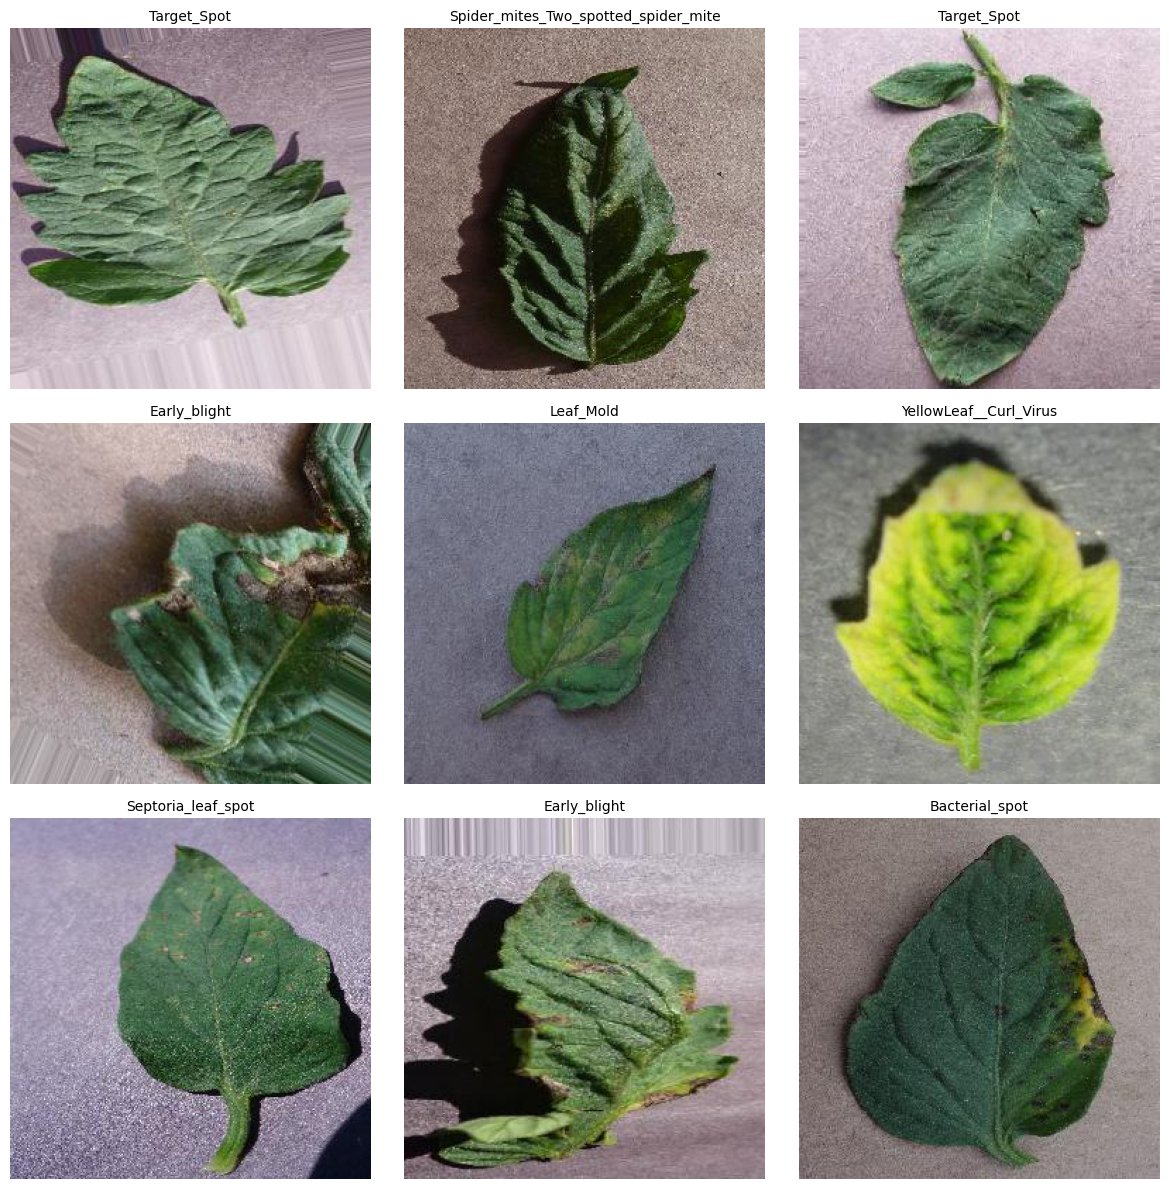

In [6]:

plt.figure(figsize=(12,12))

# Select 9 random images from the dataset
random_images = random.sample(range(len(image_paths)), 9)

for i, idx in enumerate(random_images):

    img = Image.open(image_paths[idx])

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(labels[idx], fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

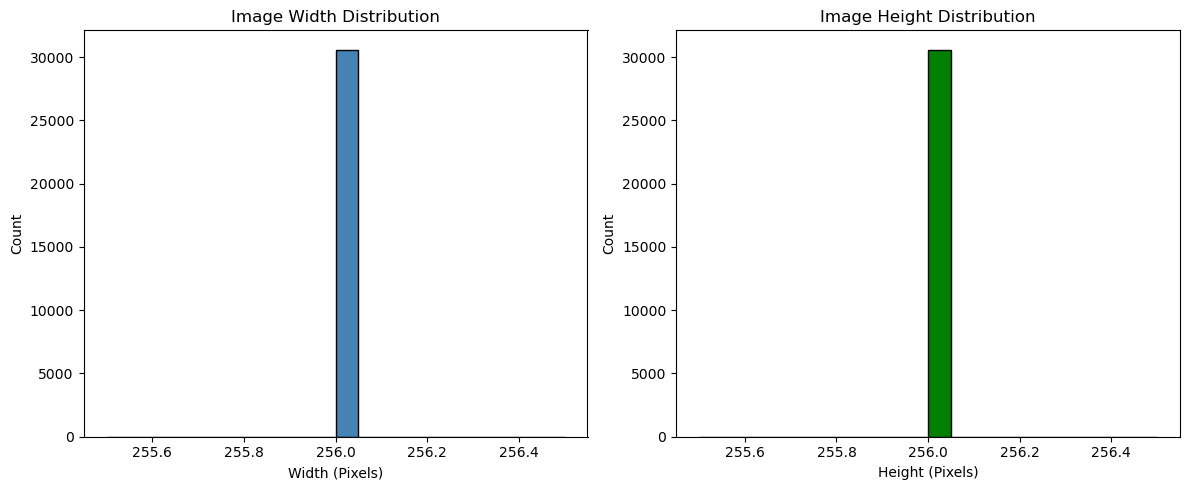

In [7]:
from PIL import Image

widths = []
heights = []

for path in image_paths:

    try:

        img = Image.open(path)

        widths.append(img.width)

        heights.append(img.height)

    except:
        pass


plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.hist(widths,
         bins=20,
         color="steelblue",
         edgecolor="black")

plt.title("Image Width Distribution")
plt.xlabel("Width (Pixels)")
plt.ylabel("Count")


plt.subplot(1,2,2)

plt.hist(heights,
         bins=20,
         color="green",
         edgecolor="black")

plt.title("Image Height Distribution")
plt.xlabel("Height (Pixels)")
plt.ylabel("Count")

plt.tight_layout()

plt.show()

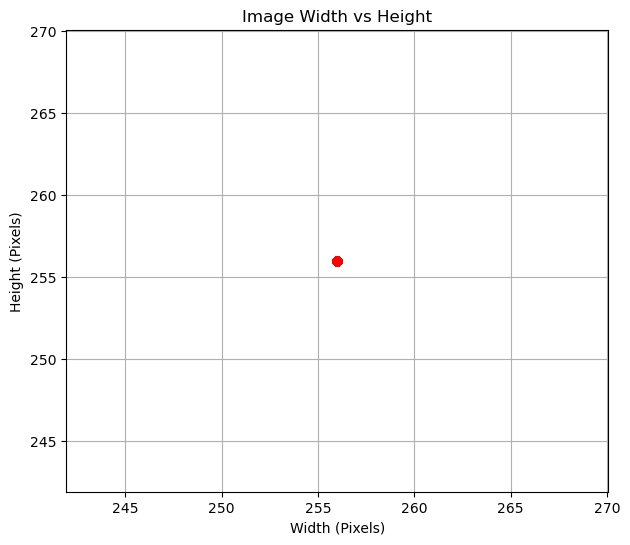

In [8]:
plt.figure(figsize=(7,6))

plt.scatter(
    widths,
    heights,
    alpha=0.6,
    color="red"
)

plt.title("Image Width vs Height")

plt.xlabel("Width (Pixels)")

plt.ylabel("Height (Pixels)")

plt.grid(True)

plt.show()

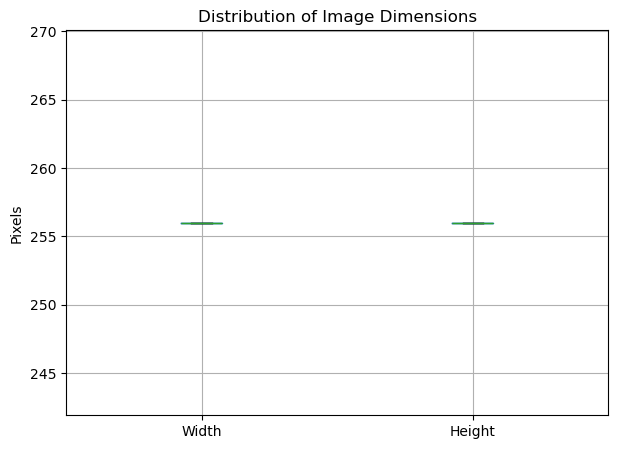

In [9]:
size_df = pd.DataFrame({
    "Width": widths,
    "Height": heights
})

plt.figure(figsize=(7,5))

size_df.boxplot()

plt.title("Distribution of Image Dimensions")

plt.ylabel("Pixels")

plt.grid(True)

plt.show()

## 4. Read class folders and image paths

Class names are taken automatically from folder names.

This fixes the original notebook's manual-label problem, where the model had 10 outputs but the manually written class-name list had 11 entries.


In [10]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_names = sorted([
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

if len(class_names) < 2:
    raise ValueError("At least two class folders are required.")

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

file_paths = []
labels = []

for class_name in class_names:
    class_folder = DATASET_DIR / class_name

    class_files = [
        str(file_path)
        for file_path in class_folder.rglob("*")
        if file_path.is_file()
        and file_path.suffix.lower() in SUPPORTED_EXTENSIONS
    ]

    file_paths.extend(class_files)
    labels.extend([class_to_index[class_name]] * len(class_files))

file_paths = np.array(file_paths)
labels = np.array(labels, dtype=np.int32)

if len(file_paths) == 0:
    raise ValueError("No supported image files were found in the dataset.")

print("Number of images:", len(file_paths))
print("Number of classes:", len(class_names))
print("Class names:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)


Number of images: 30595
Number of classes: 10
Class names:
0 -> Bacterial_spot
1 -> Early_blight
2 -> Late_blight
3 -> Leaf_Mold
4 -> Septoria_leaf_spot
5 -> Spider_mites_Two_spotted_spider_mite
6 -> Target_Spot
7 -> YellowLeaf__Curl_Virus
8 -> healthy
9 -> mosaic_virus


## 5. Check class distribution

This verifies how many images exist in every disease class.

A large difference between class counts may cause the model to favour larger classes.


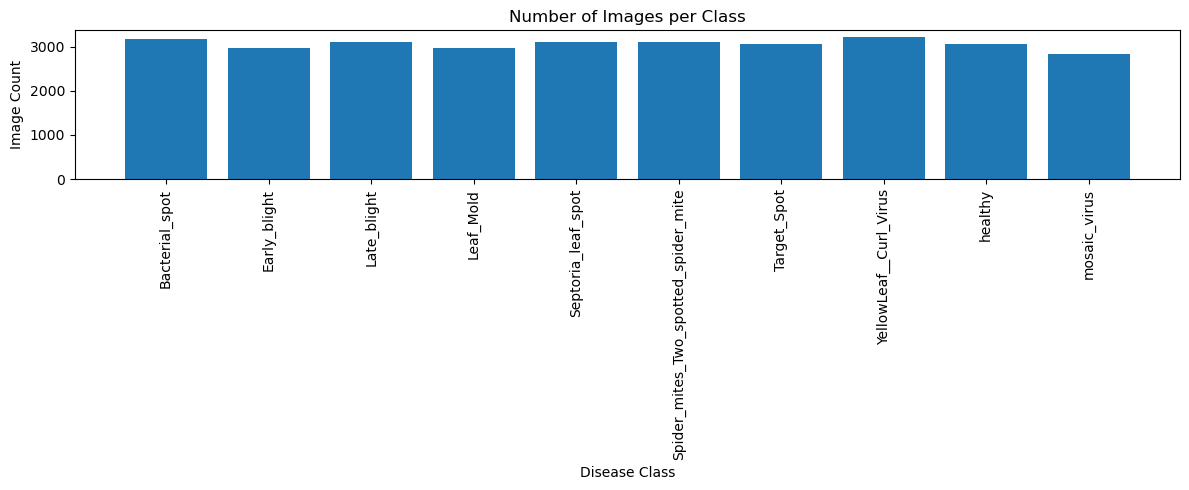

Bacterial_spot: 3164
Early_blight: 2963
Late_blight: 3098
Leaf_Mold: 2975
Septoria_leaf_spot: 3112
Spider_mites_Two_spotted_spider_mite: 3104
Target_Spot: 3064
YellowLeaf__Curl_Virus: 3208
healthy: 3066
mosaic_virus: 2841


In [11]:
class_counts = np.bincount(labels, minlength=len(class_names))

plt.figure(figsize=(12, 5))
plt.bar(class_names, class_counts)
plt.title("Number of Images per Class")
plt.xlabel("Disease Class")
plt.ylabel("Image Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

for class_name, count in zip(class_names, class_counts):
    print(f"{class_name}: {count}")


## 6. Create stratified train, validation, and test splits

Final split:

- 80% training
- 10% validation
- 10% testing

`stratify=labels` keeps approximately the same class proportion in every split.

This is safer than splitting a shuffled TensorFlow dataset using `take()` and `skip()`.


In [12]:
train_paths, temporary_paths, train_labels, temporary_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temporary_paths,
    temporary_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Total:", len(train_paths) + len(val_paths) + len(test_paths))


Training images: 24476
Validation images: 3059
Testing images: 3060
Total: 30595


## 7. Create the TensorFlow input pipeline

For each image, this function:

1. Reads the file.
2. Decodes it as RGB.
3. Resizes it to 128 × 128.
4. Converts pixel values to `float32`.
5. Returns the image and integer label.

Normalization is not done here because the model contains a `Rescaling` layer.


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

def load_and_prepare_image(file_path, label):
    image_bytes = tf.io.read_file(file_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_prepare_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_paths, train_labels, training=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)

print(train_ds.element_spec)


(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


## 8. Display sample training images

This confirms that:

- Images load correctly.
- Labels match the correct folders.
- Colour channels and image dimensions are correct.


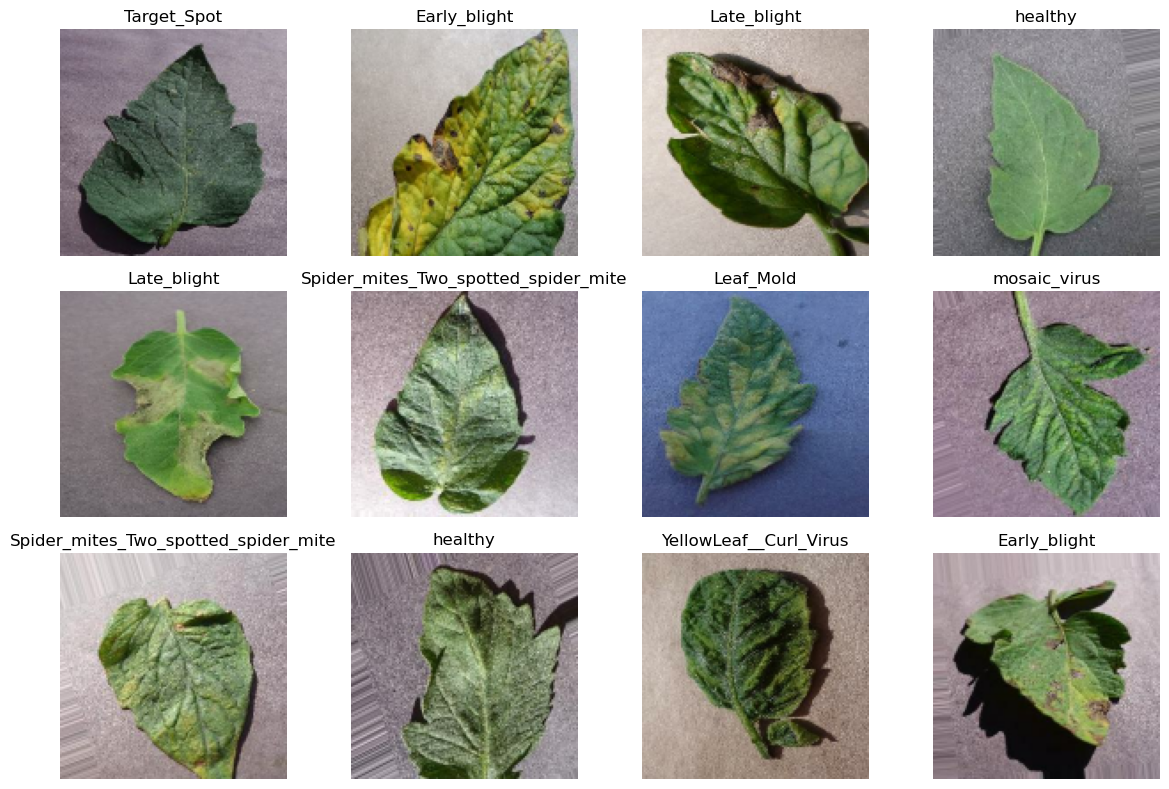

In [14]:
plt.figure(figsize=(12, 8))

for images, batch_labels in train_ds.take(1):
    number_of_images = min(12, images.shape[0])

    for index in range(number_of_images):
        plt.subplot(3, 4, index + 1)
        plt.imshow(tf.cast(images[index], tf.uint8))
        plt.title(class_names[int(batch_labels[index])])
        plt.axis("off")

plt.tight_layout()
plt.show()


## 9. Data augmentation

Data augmentation creates slightly changed versions of training images.

- Horizontal flipping changes image orientation.
- Rotation changes leaf angle.
- Zoom changes visible scale.

These transformations run only during training and help reduce overfitting.


In [15]:
data_augmentation = Sequential(
    [
        RandomFlip("horizontal"),
        RandomRotation(0.10),
        RandomZoom(0.10),
    ],
    name="data_augmentation"
)


## 10. Build the CNN model

Main layers:

- `Rescaling`: changes pixels from 0–255 to 0–1.
- `Conv2D`: learns leaf edges, spots, textures, and disease patterns.
- `BatchNormalization`: stabilizes learning.
- `MaxPooling2D`: reduces feature-map size.
- `Dropout`: reduces overfitting.
- `GlobalAveragePooling2D`: replaces a very large `Flatten` layer.
- Final `Dense`: produces one probability per class.

The final layer uses `len(class_names)`, preventing output/class-name mismatch.


In [16]:
num_classes = len(class_names)

model = Sequential([
    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    data_augmentation,
    Rescaling(1.0 / 255),

    Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),
    Dropout(0.20),

    Conv2D(128, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),
    Dropout(0.30),

    Conv2D(256, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),
    Dropout(0.35),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.40),

    Dense(num_classes, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 16, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 8, 8, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,8

 Total params: 424,522 (1.62 MB)

 Trainable params: 423,562 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)

## 11. Compile the model

- Adam updates the model weights.
- Sparse categorical cross-entropy is correct because labels are integers such as `0`, `1`, and `2`.
- Accuracy measures the percentage of correct predictions.


In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 12. Configure training callbacks

- `EarlyStopping`: stops when validation loss no longer improves.
- `ReduceLROnPlateau`: lowers the learning rate when progress slows.
- `ModelCheckpoint`: saves the model with the lowest validation loss.

All three monitor `val_loss` consistently.


In [18]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode="min",
        verbose=1
    ),

    ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    )
]


## 13. Train the model

The model learns only from `train_ds`.

`val_ds` is used to monitor generalization during training.

`test_ds` remains untouched until final evaluation.


In [ ]:
history = model.fit(
 train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/11
 37/765 ━━━━━━━━━━━━━━━━━━━━ 8:14 679ms/step - accuracy: 0.3107 - loss: 2.1268 

## 14. Plot training history

Healthy behaviour:

- Training and validation accuracy both increase.
- Training and validation loss both decrease.
- Small gaps are normal.

Possible overfitting:

- Training accuracy keeps increasing.
- Validation accuracy stops improving or decreases.
- Validation loss starts increasing.


In [ ]:
epochs_completed = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_completed,
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    epochs_completed,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_completed,
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    epochs_completed,
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 15. Load the best checkpoint and evaluate unseen test data

The test set is used only now, after training is complete.


In [ ]:
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


## 16. Classification report and confusion matrix

The classification report shows:

- Precision: how many predicted examples were correct.
- Recall: how many real examples were found.
- F1-score: balance between precision and recall.
- Support: number of test images in each class.

The confusion matrix shows exactly which diseases the model confuses.


In [ ]:
y_true = []
y_pred = []

for images, batch_labels in test_ds:
    probabilities = best_model.predict(images, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)

    y_true.extend(batch_labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    )
)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)

fig, axis = plt.subplots(figsize=(12, 10))
display.plot(
    ax=axis,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)
plt.title("Plant Disease Confusion Matrix")
plt.tight_layout()
plt.show()


## 17. Predict one new leaf image

The same image size and preprocessing used during training are used here.

Do not divide the image by 255 manually because the trained model already contains the `Rescaling` layer.


In [ ]:
def predict_plant_disease(image_path, trained_model=best_model):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image was not found: {image_path}")

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_batch = tf.expand_dims(image_array, axis=0)

    probabilities = trained_model.predict(
        image_batch,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    top_indices = np.argsort(probabilities)[::-1][:3]

    print("Top predictions:")
    for index in top_indices:
        print(
            f"{class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {predicted_class}\\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return predicted_class, confidence


IMAGE_PATH = Path(
    r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\YellowLeaf__Curl_Virus\img_952.jpg")
predicted_class, confidence = predict_plant_disease(
 r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\healthy\img_999.jpg")
# Test Image 1
predicted_class, confidence = predict_plant_disease(
    r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\mosaic_virus\img_993.jpg")

# Test Image 2
predicted_class, confidence = predict_plant_disease(
    r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\Target_Spot\img_984.jpg")


predicted_class, confidence = predict_plant_disease(
    r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\Bacterial_spot\img_946.jpg")

predicted_class, confidence = predict_plant_disease(
    r"C:\Users\shaha\Downloads\PLANT DISEASE\plant disease\Bacterial_spot\img_946.jpg")

## 18. Save the final model and class names

Saving class names is essential because output index `0`, `1`, `2`, etc. must map to the same disease names when the model is used later in Streamlit or another application.


In [ ]:
best_model.save(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=4)

print("Model saved to:", FINAL_MODEL_PATH)
print("Class names saved to:", CLASS_NAMES_PATH)


## 19. Load the saved model later

Use this cell in a new notebook or application.


In [ ]:
loaded_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    loaded_class_names = json.load(file)

print("Model and class names loaded successfully.")
print(loaded_class_names)


In [ ]:
# Evaluate Training Data
train_loss, train_accuracy = best_model.evaluate(train_ds)

# Evaluate Validation Data
val_loss, val_accuracy = best_model.evaluate(val_ds)

# Evaluate Test Data
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Train Accuracy      : {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")
print(f"Test Accuracy       : {test_accuracy * 100:.2f}%")

print(f"\nTrain Loss      : {train_loss:.4f}")
print(f"Validation Loss : {val_loss:.4f}")
print(f"Test Loss       : {test_loss:.4f}")

## Conclusion

The CNN model was successfully trained to classify ten plant leaf disease classes.

The final model was evaluated using training, validation, and test datasets and achieved:

- Training Accuracy: 95.31%
- Validation Accuracy: 94.77%
- Test Accuracy: 94.64%

The model achieved a test loss of 0.1644. The similar performance across the training, validation, and test datasets indicates good generalization without significant overfitting.

Data augmentation, batch normalization, dropout, learning-rate reduction, early stopping, and model checkpointing were used to improve training stability and model generalization.

The trained model can also predict the disease class of individual leaf images and provide a confidence score.

Overall, the model performs well on the PlantVillage dataset. However, further testing with unseen real-world field images is recommended before practical deployment.

## Future Work

- Evaluate the model using unseen real-world leaf photographs to test its practical performance.
- Compare the custom CNN model with transfer learning architectures such as ResNet and EfficientNet, as well as Vision Transformer (ViT).
- Deploy the trained model as an interactive web application using Streamlit.
- Integrate disease descriptions, prevention methods, and treatment recommendations for predicted diseases.
- Implement Grad-CAM to visualize the regions of the leaf that influence the model's predictions.